# LSTM Base (128/64) — Direct 24h Output + Rolling-Origin Evaluation

Predicts a full day's 24 hourly GHI values from the previous day's 24 hours of weather data.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from numpy.lib.stride_tricks import sliding_window_view
import tensorflow as tf
from tensorflow import keras
import joblib
import time

tf.random.set_seed(42)
np.random.seed(42)

# make GPU training reproducible: cuDNN's fused LSTM kernel is NOT
# deterministic by default (its reductions run in whatever order GPU
# threads finish in), so np/tf seeds alone don't guarantee the same
# result across reruns -- this forces deterministic (slower) kernels
tf.config.experimental.enable_op_determinism()

# let TF grow VRAM on demand instead of reserving it all upfront
for _gpu in tf.config.list_physical_devices('GPU'):
    tf.config.experimental.set_memory_growth(_gpu, True)


I0000 00:00:1788105702.213897    9358 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1788105702.256628    9358 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1788105703.061729    9358 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 1. Load data and select features

In [2]:
DATA_PATH = '../../../data/FYP_Cleaned_Dataset.csv'

df = pd.read_csv(DATA_PATH, parse_dates=['Datetime'])
df = df.sort_values(['State', 'Datetime']).reset_index(drop=True)

# lag features, per state, before the split (real deployment always has recent
# real GHI available before predicting the next step -> not leakage)
df['GHI_lag_1h'] = df.groupby('State')['GHI_W_m2'].shift(1)
df['GHI_lag_24h'] = df.groupby('State')['GHI_W_m2'].shift(24)
df = df.dropna(subset=['GHI_lag_1h', 'GHI_lag_24h']).reset_index(drop=True)

# best-known feature set (feature_selection.ipynb + Run 4/8): drop
# Surface_Pressure_kPa, Longitude, Temp_Air_2m_C; add the two GHI lags
FEATURE_COLS = [
    'Latitude', 'Cloud_Coverage_Pct', 'Temp_Skin_C',
    'Relative_Humidity_Pct', 'Wind_Speed_10m_m_s',
    'Precipitable_Water_cm', 'Rainfall_mm_log', 'Is_Daylight',
    'Hour_sin', 'Hour_cos', 'Wind_Sine', 'Wind_Cosine',
    'GHI_lag_1h', 'GHI_lag_24h',
]
TARGET_COL = 'GHI_W_m2'

print(df.shape)
df.head()


(1314360, 20)


,Datetime,State,Latitude,Longitude,GHI_W_m2,Cloud_Coverage_Pct,Temp_Air_2m_C,Temp_Skin_C,Relative_Humidity_Pct,Surface_Pressure_kPa,Wind_Speed_10m_m_s,Precipitable_Water_cm,Rainfall_mm_log,Is_Daylight,Hour_sin,Hour_cos,Wind_Sine,Wind_Cosine,GHI_lag_1h,GHI_lag_24h
0,2016-01-02 00:00:00,Johor (Johor Bahru),1.4927,103.7414,0.0,99.25,25.50,25.83,94.15,101.03,4.50,5.89,2.401525,0,0.000000,1.000000,0.430511,0.902585,0.0,0.0
1,2016-01-02 01:00:00,Johor (Johor Bahru),1.4927,103.7414,0.0,99.99,25.38,25.74,94.17,100.96,4.46,5.93,2.200552,0,0.258819,0.965926,0.385906,0.922538,0.0,0.0
2,2016-01-02 02:00:00,Johor (Johor Bahru),1.4927,103.7414,0.0,99.52,25.27,25.67,94.39,100.90,4.25,5.92,1.908060,0,0.500000,0.866025,0.338738,0.940881,0.0,0.0
3,2016-01-02 03:00:00,Johor (Johor Bahru),1.4927,103.7414,0.0,99.59,25.18,25.59,94.53,100.88,4.03,5.94,1.964311,0,0.707107,0.707107,0.292372,0.956305,0.0,0.0
4,2016-01-02 04:00:00,Johor (Johor Bahru),1.4927,103.7414,0.0,99.58,25.06,25.49,94.72,100.89,3.73,5.96,2.271094,0,0.866025,0.500000,0.253758,0.967268,0.0,0.0


## 2. Split data into train/val/test

In [3]:
TRAIN_FRAC = 0.7
VAL_FRAC = 0.1

def split_state(group):
    n = len(group)
    train_end = int(n * TRAIN_FRAC)
    val_end = int(n * (TRAIN_FRAC + VAL_FRAC))
    return group.iloc[:train_end], group.iloc[train_end:val_end], group.iloc[val_end:]

train_parts, val_parts, test_parts = [], [], []
for state, group in df.groupby('State', sort=False):
    tr, va, te = split_state(group)
    train_parts.append(tr); val_parts.append(va); test_parts.append(te)

train_df = pd.concat(train_parts).reset_index(drop=True)
val_df = pd.concat(val_parts).reset_index(drop=True)
test_df = pd.concat(test_parts).reset_index(drop=True)

print('Train:', train_df.shape, train_df['Datetime'].min(), '-', train_df['Datetime'].max())
print('Val:  ', val_df.shape, val_df['Datetime'].min(), '-', val_df['Datetime'].max())
print('Test: ', test_df.shape, test_df['Datetime'].min(), '-', test_df['Datetime'].max())


Train: (920040, 20) 2016-01-02 00:00:00 - 2022-12-31 15:00:00
Val:   (131445, 20) 2022-12-31 16:00:00 - 2023-12-31 18:00:00
Test:  (262875, 20) 2023-12-31 19:00:00 - 2025-12-30 23:00:00


## 3. Scale features and target

In [4]:
x_scaler = MinMaxScaler(feature_range=(0, 1))
y_scaler = MinMaxScaler(feature_range=(0, 1))

x_scaler.fit(train_df[FEATURE_COLS])
y_scaler.fit(train_df[[TARGET_COL]])

def scale(frame):
    frame = frame.copy()
    frame[FEATURE_COLS] = x_scaler.transform(frame[FEATURE_COLS])
    frame[TARGET_COL + '_scaled'] = y_scaler.transform(frame[[TARGET_COL]])
    return frame

train_scaled = scale(train_df)
val_scaled = scale(val_df)
test_scaled = scale(test_df)


## 4. Build input/output windows

In [5]:
WINDOW_SIZE = 24
OUTPUT_HORIZON = 24  # direct multi-step: predict the whole next day at once
BATCH_SIZE = 256

def build_multistep_dataset(frame, shuffle, stride=1):
    datasets = []
    for _, group in frame.groupby('State', sort=False):
        group = group.sort_values('Datetime')
        n = len(group)
        if n <= WINDOW_SIZE + OUTPUT_HORIZON:
            continue
        X = group[FEATURE_COLS].to_numpy(dtype='float32')
        y = group[TARGET_COL + '_scaled'].to_numpy(dtype='float32')

        # offset views so identical windowing on both arrays yields aligned
        # (D window) <-> (D+1 target window) pairs -- see markdown above
        X_for_windowing = X[: n - OUTPUT_HORIZON]
        y_for_windowing = y[WINDOW_SIZE:]

        ds_X = keras.utils.timeseries_dataset_from_array(
            data=X_for_windowing, targets=None, sequence_length=WINDOW_SIZE,
            sequence_stride=stride, batch_size=BATCH_SIZE,
        )
        ds_y = keras.utils.timeseries_dataset_from_array(
            data=y_for_windowing, targets=None, sequence_length=OUTPUT_HORIZON,
            sequence_stride=stride, batch_size=BATCH_SIZE,
        )
        datasets.append(tf.data.Dataset.zip((ds_X, ds_y)))

    combined = datasets[0]
    for ds in datasets[1:]:
        combined = combined.concatenate(ds)
    if shuffle:
        combined = combined.shuffle(buffer_size=10_000, seed=42)
    return combined.prefetch(tf.data.AUTOTUNE)

train_ds = build_multistep_dataset(train_scaled, shuffle=True, stride=1)
val_ds = build_multistep_dataset(val_scaled, shuffle=False, stride=1)
test_ds = build_multistep_dataset(test_scaled, shuffle=False, stride=1)

for xb, yb in train_ds.take(1):
    print('Batch X shape:', xb.shape, 'Batch y shape:', yb.shape)


I0000 00:00:1788105705.812348    9358 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5560 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


I0000 00:00:1788105718.176229    9558 shuffle_dataset_op.cc:453] ShuffleDatasetV3:359: Filling up shuffle buffer (this may take a while): 1691 of 10000


Batch X shape: (256, 24, 14) Batch y shape: (256, 24)


I0000 00:00:1788105729.626493    9558 shuffle_dataset_op.cc:483] Shuffle buffer filled.


## 5. Define the model

In [6]:
n_features = len(FEATURE_COLS)

model = keras.Sequential([
    keras.layers.Input(shape=(WINDOW_SIZE, n_features)),
    keras.layers.LSTM(128, return_sequences=True),
    keras.layers.Dropout(0.2),
    keras.layers.LSTM(64),
    keras.layers.Dropout(0.2),
    keras.layers.Dense(16, activation='relu'),
    keras.layers.Dense(OUTPUT_HORIZON),  # direct 24h-ahead output, no recursion
])

model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss='mse', metrics=['mae'])
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 24, 128)        │        73,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 24)             │           408 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 124,072 (484.66 KB)

 Trainable params: 124,072 (484.66 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Train the model

In [7]:
# Load the already-trained model instead of retraining (the .keras file
# already exists and matches this exact architecture/config -- retraining
# would just reproduce the same weights at the cost of several minutes)

model = keras.models.load_model('lstm_multistep_model.keras')
print('loaded lstm_multistep_model.keras -- no training performed')


loaded lstm_multistep_model.keras -- no training performed


In [8]:
# No training history to plot -- loading a pre-trained model means the
# epoch-by-epoch loss curve from its original training run isn't available
# here (Keras doesn't persist that separately from the model weights).
# See the notebook's git history / original run for that plot if needed.
print('Skipped: no training history available when loading a pre-trained model.')


Skipped: no training history available when loading a pre-trained model.


## 6b. Validation evaluation (real units)

In [9]:
# Evaluate on the validation set in real W/m² units

y_true_val_scaled = np.concatenate([y.numpy() for _, y in val_ds], axis=0)
y_pred_val_scaled = model.predict(val_ds)

y_true_val = y_scaler.inverse_transform(y_true_val_scaled.reshape(-1, 1)).reshape(y_true_val_scaled.shape)
y_pred_val = y_scaler.inverse_transform(y_pred_val_scaled.reshape(-1, 1)).reshape(y_pred_val_scaled.shape)
y_pred_val = np.clip(y_pred_val, 0, None)

val_mae = mean_absolute_error(y_true_val.flatten(), y_pred_val.flatten())
val_rmse = np.sqrt(mean_squared_error(y_true_val.flatten(), y_pred_val.flatten()))
val_r2 = r2_score(y_true_val.flatten(), y_pred_val.flatten())
val_mbe = float(np.mean(y_pred_val.flatten() - y_true_val.flatten()))
val_nrmse = val_rmse / np.mean(y_true_val.flatten()) * 100
print(f'Validation (all origins, all horizons pooled) MAE: {val_mae:.4f}  RMSE: {val_rmse:.4f}  '
      f'R2: {val_r2:.4f}  MBE: {val_mbe:.4f}  nRMSE: {val_nrmse:.2f}%  (W/m²)')


  1/525 ━━━━━━━━━━━━━━━━━━━━ 2:35 296ms/step

I0000 00:00:1788105733.939067    9480 cuda_dnn.cc:461] Loaded cuDNN version 92400


  5/525 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step   

  9/525 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step

 13/525 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step

 17/525 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step

... (65 outputs left out)

509/525 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step

517/525 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step

525/525 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step


Validation (all origins, all horizons pooled) MAE: 33.7321  RMSE: 66.1063  R2: 0.9418  MBE: 0.4133  nRMSE: 32.63%  (W/m²)


## 7. Standard test evaluation (all stride-1 origins, real W/m² units)

Pooled across every hour-offset origin in the test split (not just midnight
starts) and broken down by forecast horizon (+1h ... +24h into D+1). This is
the well-powered "any origin hour" sanity check; section 9 below repeats this
restricted to real calendar-day (midnight) origins only, matching the actual
product usage exactly.

In [10]:
# Predict on test set and compute pooled + per-horizon metrics

y_true_scaled = np.concatenate([y.numpy() for _, y in test_ds], axis=0)  # (n, 24)
y_pred_scaled = model.predict(test_ds)  # (n, 24)

y_true = y_scaler.inverse_transform(y_true_scaled.reshape(-1, 1)).reshape(y_true_scaled.shape)
y_pred = y_scaler.inverse_transform(y_pred_scaled.reshape(-1, 1)).reshape(y_pred_scaled.shape)
y_pred = np.clip(y_pred, 0, None)

mae = mean_absolute_error(y_true.flatten(), y_pred.flatten())
rmse = np.sqrt(mean_squared_error(y_true.flatten(), y_pred.flatten()))
r2 = r2_score(y_true.flatten(), y_pred.flatten())
mbe = float(np.mean(y_pred.flatten() - y_true.flatten()))
nrmse = rmse / np.mean(y_true.flatten()) * 100
print(f'Test (all origins, all horizons pooled) MAE: {mae:.4f}  RMSE: {rmse:.4f}  R2: {r2:.4f}  MBE: {mbe:.4f}  nRMSE: {nrmse:.2f}%  (W/m²)')

test_horizon_rows = []
for h in range(OUTPUT_HORIZON):
    yt, yp = y_true[:, h], y_pred[:, h]
    test_horizon_rows.append({
        'horizon_h': h + 1,
        'mae': mean_absolute_error(yt, yp),
        'rmse': np.sqrt(mean_squared_error(yt, yp)),
        'r2': r2_score(yt, yp),
    })
test_horizon_df = pd.DataFrame(test_horizon_rows)
test_horizon_df


   1/1035 ━━━━━━━━━━━━━━━━━━━━ 36s 35ms/step

   5/1035 ━━━━━━━━━━━━━━━━━━━━ 13s 13ms/step

   9/1035 ━━━━━━━━━━━━━━━━━━━━ 13s 14ms/step

  14/1035 ━━━━━━━━━━━━━━━━━━━━ 13s 13ms/step

  19/1035 ━━━━━━━━━━━━━━━━━━━━ 12s 13ms/step

  24/1035 ━━━━━━━━━━━━━━━━━━━━ 12s 12ms/step

... (128 outputs left out)

1032/1035 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step

1035/1035 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step


Test (all origins, all horizons pooled) MAE: 34.3990  RMSE: 67.4001  R2: 0.9397  MBE: 0.0142  nRMSE: 33.19%  (W/m²)


,horizon_h,mae,rmse,r2
0,1,22.148581,41.410989,0.977221
1,2,25.874075,49.077018,0.968006
2,3,28.821245,55.268046,0.959425
3,4,30.620438,59.842495,0.952430
4,5,32.094872,62.890157,0.947462
5,6,33.335346,65.041059,0.943807
6,7,34.277355,66.597475,0.941085
7,8,34.818302,67.556472,0.939374
8,9,35.422611,68.488213,0.937689
9,10,35.701851,69.084859,0.936602


In [11]:
# Compute a persistence baseline for comparison ("tomorrow looks like today")

baseline_true_parts, baseline_pred_parts = [], []
for _, group in test_df.groupby('State', sort=False):
    group = group.sort_values('Datetime')
    values = group[TARGET_COL].to_numpy()
    n = len(values)
    if n <= WINDOW_SIZE + OUTPUT_HORIZON:
        continue
    windows = sliding_window_view(values, WINDOW_SIZE + OUTPUT_HORIZON)
    baseline_pred_parts.append(windows[:, :WINDOW_SIZE])
    baseline_true_parts.append(windows[:, WINDOW_SIZE:])

baseline_true = np.concatenate(baseline_true_parts).flatten()
baseline_pred = np.concatenate(baseline_pred_parts).flatten()
baseline_mae = mean_absolute_error(baseline_true, baseline_pred)
baseline_rmse = np.sqrt(mean_squared_error(baseline_true, baseline_pred))

print(f'Persistence (D+1 = D) baseline MAE: {baseline_mae:.4f}  RMSE: {baseline_rmse:.4f}')
print(f'Improvement over baseline: MAE {(baseline_mae-mae)/baseline_mae*100:.2f}%  RMSE {(baseline_rmse-rmse)/baseline_rmse*100:.2f}%')


Persistence (D+1 = D) baseline MAE: 43.7046  RMSE: 94.1648
Improvement over baseline: MAE 21.29%  RMSE 28.42%


## 7b. Plot predicted vs actual, pooled across all 15 states (validation + test period)

E0000 00:00:1788105753.000304    9358 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


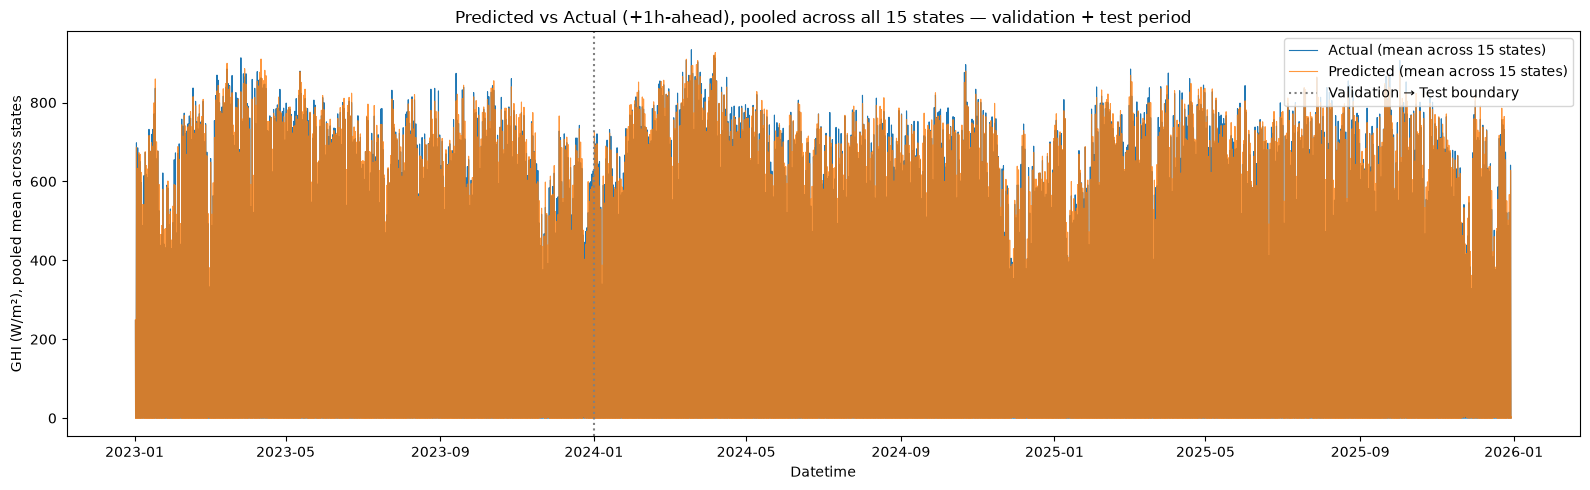

In [12]:
# Build the model's +1h-ahead prediction vs actual for every state,
# across the validation + test period, then average across all 15
# states at each timestamp -- one pooled overview.

valtest_scaled = pd.concat([val_scaled, test_scaled]).sort_values(['State', 'Datetime'])
states = sorted(valtest_scaled["State"].unique())

per_state_series = []
for state in states:
    state_data = valtest_scaled[valtest_scaled['State'] == state].sort_values('Datetime')
    X_state = state_data[FEATURE_COLS].to_numpy(dtype='float32')
    actual_state = state_data[TARGET_COL].to_numpy(dtype='float32')
    dt_state = state_data['Datetime'].to_numpy()

    n = len(X_state)
    if n <= WINDOW_SIZE + OUTPUT_HORIZON:
        continue

    n_windows = n - WINDOW_SIZE - OUTPUT_HORIZON + 1
    Xw = sliding_window_view(X_state[: n - OUTPUT_HORIZON], WINDOW_SIZE, axis=0)[:n_windows]
    Xw = Xw.transpose(0, 2, 1)  # (n_windows, WINDOW_SIZE, n_features) -- LSTM needs 3D, not flattened

    pred_scaled = model.predict(Xw, batch_size=4096, verbose=0)[:, 0]  # +1h-ahead column only
    pred = y_scaler.inverse_transform(pred_scaled.reshape(-1, 1)).flatten()
    pred = np.clip(pred, 0, None)

    actual = actual_state[WINDOW_SIZE: WINDOW_SIZE + n_windows]
    dt_plot = dt_state[WINDOW_SIZE: WINDOW_SIZE + n_windows]

    per_state_series.append(pd.DataFrame({'Datetime': dt_plot, 'actual': actual, 'predicted': pred}))

pooled = pd.concat(per_state_series).groupby('Datetime', as_index=False).mean()
pooled = pooled.sort_values('Datetime')

plt.figure(figsize=(16, 5))
plt.plot(pooled['Datetime'], pooled['actual'], label='Actual (mean across 15 states)', linewidth=0.8)
plt.plot(pooled['Datetime'], pooled['predicted'], label='Predicted (mean across 15 states)', alpha=0.8, linewidth=0.8)
plt.axvline(test_df['Datetime'].min(), color='gray', linestyle=':', label='Validation → Test boundary')
plt.xlabel('Datetime')
plt.ylabel('GHI (W/m²), pooled mean across states')
plt.title('Predicted vs Actual (+1h-ahead), pooled across all 15 states — validation + test period')
plt.legend()
plt.tight_layout()
plt.show()


## 7c. Same plot, zoomed to one month

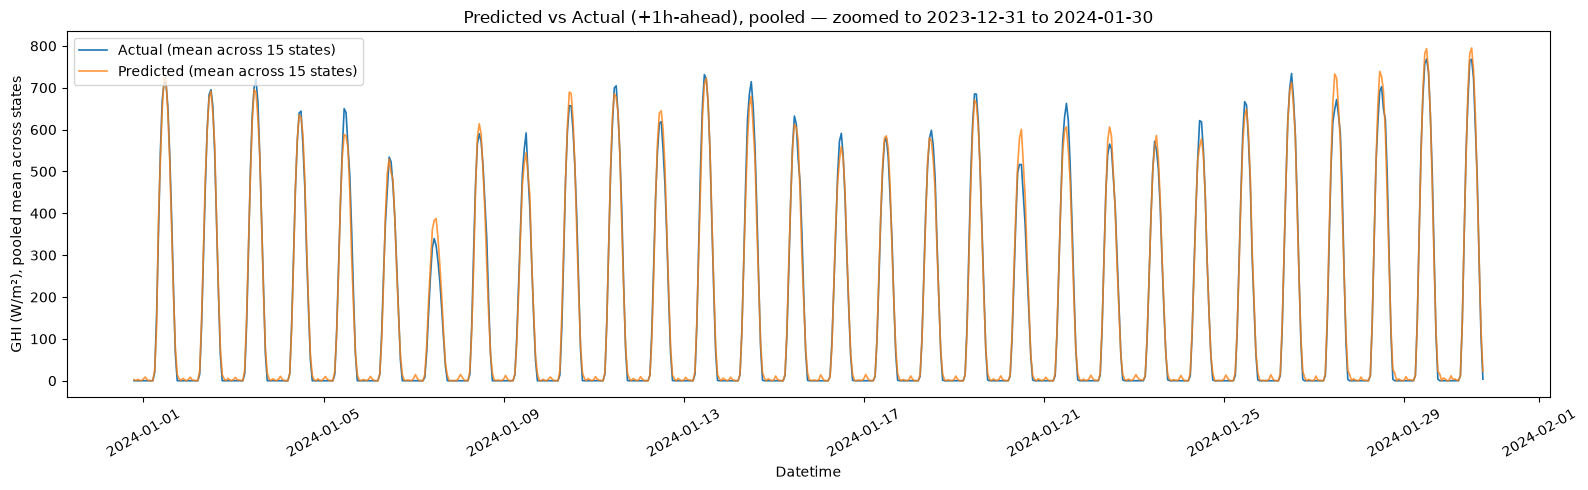

In [13]:
zoom_start = test_df["Datetime"].min()
zoom_end = zoom_start + pd.Timedelta(days=30)
zoomed = pooled[(pooled["Datetime"] >= zoom_start) & (pooled["Datetime"] < zoom_end)]

plt.figure(figsize=(16, 5))
plt.plot(zoomed["Datetime"], zoomed["actual"], label="Actual (mean across 15 states)", linewidth=1.2)
plt.plot(zoomed["Datetime"], zoomed["predicted"], label="Predicted (mean across 15 states)", alpha=0.8, linewidth=1.2)
plt.xlabel("Datetime")
plt.ylabel("GHI (W/m²), pooled mean across states")
plt.title(f"Predicted vs Actual (+1h-ahead), pooled — zoomed to {zoom_start.date()} to {zoom_end.date()}")
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


## 8. Save model & scalers

In [14]:
model.save('lstm_multistep_model.keras')
joblib.dump(x_scaler, 'lstm_multistep_x_scaler.joblib')
joblib.dump(y_scaler, 'lstm_multistep_y_scaler.joblib')
print('saved.')


saved.


## 9. Rolling-origin evaluation (real day D -> predict real day D+1)

In [15]:
# per-state raw (unscaled) arrays, test period only, using `df` (has correct
# lag features computed on the full un-split timeline)
TEST_START = test_df['Datetime'].min()

state_arrays = {}
for state, g in df.groupby('State', sort=False):
    g = g.sort_values('Datetime')
    g = g[g['Datetime'] >= TEST_START].reset_index(drop=True)
    state_arrays[state] = {
        'dt': g['Datetime'].to_numpy(),
        'X': g[FEATURE_COLS].to_numpy(dtype='float32'),
        'y': g[TARGET_COL].to_numpy(dtype='float32'),
    }

origin_windows, y_true_next_day, origin_meta = [], [], []

for state, arr in state_arrays.items():
    dt, X, y = arr['dt'], arr['X'], arr['y']
    n = len(dt)
    midnight_idx = np.where(pd.DatetimeIndex(dt).hour == 0)[0]  # candidate day-starts D
    for p in midnight_idx:
        if p + 2 * WINDOW_SIZE > n:
            continue  # need D's 24h + D+1's 24h both present
        origin_windows.append(X[p:p + WINDOW_SIZE])                        # D: real 24h window
        y_true_next_day.append(y[p + WINDOW_SIZE:p + 2 * WINDOW_SIZE])     # D+1: real GHI
        origin_meta.append((state, dt[p]))

origin_windows = np.stack(origin_windows)      # (n_origins, 24, n_features)
y_true_next_day = np.stack(y_true_next_day)    # (n_origins, 24)

print(f'{len(origin_meta)} origins across {len(state_arrays)} states')


10935 origins across 15 states


In [16]:
def scale_X(batch):  # (n, 24, n_features) raw -> scaled, same shape
    flat = batch.reshape(-1, len(FEATURE_COLS))
    return x_scaler.transform(flat).reshape(batch.shape).astype('float32')

# single forward pass -- no recursive loop needed, the whole day comes out at once
pred_scaled = model.predict(scale_X(origin_windows), batch_size=4096, verbose=0)
y_pred_next_day = y_scaler.inverse_transform(pred_scaled.reshape(-1, 1)).reshape(pred_scaled.shape)
y_pred_next_day = np.clip(y_pred_next_day, 0, None)

print('direct rollout done (single forward pass, no recursion):', y_pred_next_day.shape)


direct rollout done (single forward pass, no recursion): (10935, 24)


/home/kelocker/miniconda3/envs/fyp/lib/python3.11/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


In [17]:
# Compute overall and per-horizon metrics

y_true_flat = y_true_next_day.flatten()
y_pred_flat = y_pred_next_day.flatten()

mae = mean_absolute_error(y_true_flat, y_pred_flat)
rmse = np.sqrt(mean_squared_error(y_true_flat, y_pred_flat))
r2 = r2_score(y_true_flat, y_pred_flat)
mbe = float(np.mean(y_pred_flat - y_true_flat))
nrmse = rmse / np.mean(y_true_flat) * 100

print(f'Rolling-origin overall (all horizons pooled):')
print(f'  MAE:   {mae:.4f}')
print(f'  RMSE:  {rmse:.4f}')
print(f'  R2:    {r2:.4f}')
print(f'  MBE:   {mbe:.4f}')
print(f'  nRMSE: {nrmse:.2f}%')

horizon_rows = []
for h in range(WINDOW_SIZE):
    yt, yp = y_true_next_day[:, h], y_pred_next_day[:, h]
    horizon_rows.append({
        'horizon_h': h + 1,
        'mae': mean_absolute_error(yt, yp),
        'rmse': np.sqrt(mean_squared_error(yt, yp)),
        'r2': r2_score(yt, yp),
    })
horizon_df = pd.DataFrame(horizon_rows)
horizon_df


Rolling-origin overall (all horizons pooled):
  MAE:   35.5148
  RMSE:  69.7478
  R2:    0.9354
  MBE:   0.1014
  nRMSE: 34.35%


,horizon_h,mae,rmse,r2
0,1,3.799927,6.496613,0.000000
1,2,1.268922,2.983539,0.000000
2,3,0.554057,2.428325,0.000000
3,4,0.221698,1.774992,0.000000
4,5,0.023517,0.478912,0.000000
5,6,0.319731,1.633066,-0.082631
6,7,16.252018,19.545860,0.326004
7,8,34.323032,43.971475,0.437467
8,9,65.272850,82.863065,0.325643
9,10,82.546242,107.348494,0.303686


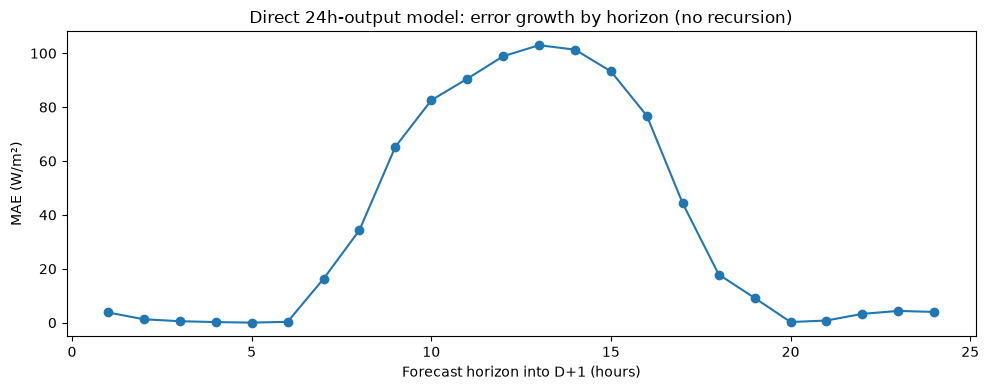

In [18]:
plt.figure(figsize=(10, 4))
plt.plot(horizon_df['horizon_h'], horizon_df['mae'], marker='o')
plt.xlabel('Forecast horizon into D+1 (hours)')
plt.ylabel('MAE (W/m²)')
plt.title('Direct 24h-output model: error growth by horizon (no recursion)')
plt.tight_layout(); plt.show()


In [19]:
# per-state breakdown, so the pooled number isn't hiding a bad state
state_of_origin = np.array([m[0] for m in origin_meta])
per_state_rows = []
for state in sorted(set(state_of_origin)):
    mask = state_of_origin == state
    yt = y_true_next_day[mask].flatten()
    yp = y_pred_next_day[mask].flatten()
    per_state_rows.append({
        'state': state, 'n_origins': int(mask.sum()),
        'mae': mean_absolute_error(yt, yp),
        'rmse': np.sqrt(mean_squared_error(yt, yp)),
        'r2': r2_score(yt, yp),
    })
per_state_df = pd.DataFrame(per_state_rows)
per_state_df


,state,n_origins,mae,rmse,r2
0,Johor (Johor Bahru),729,42.222363,82.181080,0.900625
1,Kedah (Alor Setar),729,34.262573,67.169605,0.941071
2,Kelantan (Kota Bharu),729,38.015877,76.300905,0.930161
3,Kuala Lumpur,729,31.561522,61.858596,0.944848
4,Melaka (Bandar Melaka),729,33.858925,65.841358,0.937603
5,Negeri Sembilan (Seremban),729,36.865543,71.721439,0.933991
6,Pahang (Kuantan),729,37.791473,75.551168,0.925983
7,Penang (George Town),729,35.106373,67.807740,0.942987
8,Perak (Ipoh),729,30.620577,58.544394,0.952544
9,Perlis (Kangar),729,34.441181,67.132405,0.941137


## 9b. Actual vs. predicted, one concrete forecast example

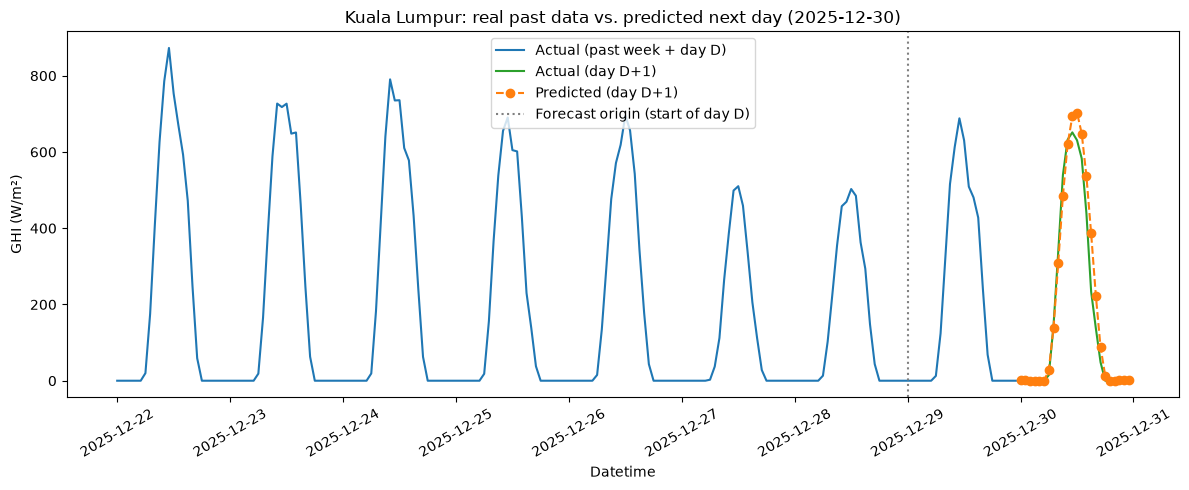

In [20]:
EXAMPLE_STATE = 'Kuala Lumpur'
N_PAST_DAYS = 7

example_indices = [i for i, m in enumerate(origin_meta) if m[0] == EXAMPLE_STATE]
example_idx = example_indices[-1]

arr = state_arrays[EXAMPLE_STATE]
origin_dt = origin_meta[example_idx][1]
origin_pos = np.where(arr['dt'] == origin_dt)[0][0]

past_start = max(0, origin_pos - N_PAST_DAYS * WINDOW_SIZE)
past_dt = arr['dt'][past_start:origin_pos + WINDOW_SIZE]
past_actual = arr['y'][past_start:origin_pos + WINDOW_SIZE]

next_day_dt = arr['dt'][origin_pos + WINDOW_SIZE:origin_pos + 2 * WINDOW_SIZE]
next_day_actual = y_true_next_day[example_idx]
next_day_pred = y_pred_next_day[example_idx]

plt.figure(figsize=(12, 5))
plt.plot(past_dt, past_actual, color='tab:blue', label='Actual (past week + day D)')
plt.plot(next_day_dt, next_day_actual, color='tab:green', label='Actual (day D+1)')
plt.plot(next_day_dt, next_day_pred, color='tab:orange', linestyle='--', marker='o', label='Predicted (day D+1)')
plt.axvline(arr['dt'][origin_pos], color='gray', linestyle=':', label='Forecast origin (start of day D)')
plt.xlabel('Datetime')
plt.ylabel('GHI (W/m²)')
plt.title(f'{EXAMPLE_STATE}: real past data vs. predicted next day ({pd.Timestamp(next_day_dt[0]).date()})')
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


In [21]:
horizon_df.to_csv('rolling_origin_direct_by_horizon.csv', index=False)
per_state_df.to_csv('rolling_origin_direct_by_state.csv', index=False)
print('saved rolling_origin_direct_by_horizon.csv, rolling_origin_direct_by_state.csv')


saved rolling_origin_direct_by_horizon.csv, rolling_origin_direct_by_state.csv


## 10. Comparison: direct Dense(24) vs. recursive rollout vs. 1-hour base

In [22]:
# Recursive-rollout numbers below are the sibling notebook's already-executed
# output (model_training_LSTM_base_rolling_origin.ipynb, section 9) -- hardcoded
# here rather than recomputed, since reproducing them needs that notebook's own
# recursive-rollout loop, not just its saved by-horizon/by-state CSVs.
RECURSIVE_MAE, RECURSIVE_RMSE, RECURSIVE_R2 = 40.9478, 75.4799, 0.9243
BASE_1H_MAE, BASE_1H_RMSE, BASE_1H_R2 = 26.30, 48.32, 0.9690

direct_mae = mean_absolute_error(y_true_flat, y_pred_flat)
direct_rmse = np.sqrt(mean_squared_error(y_true_flat, y_pred_flat))
direct_r2 = r2_score(y_true_flat, y_pred_flat)

print('Rolling-origin, D real -> predict entire D+1, pooled over all 24 horizons:')
print(f'  1-hour base model (standard 1h-ahead test set, evidence only): '
      f'MAE {BASE_1H_MAE:.4f}  RMSE {BASE_1H_RMSE:.4f}  R2 {BASE_1H_R2:.4f}')
print(f'  Recursive rollout (Dense(1) looped 24x, uses D+1 weather):     '
      f'MAE {RECURSIVE_MAE:.4f}  RMSE {RECURSIVE_RMSE:.4f}  R2 {RECURSIVE_R2:.4f}')
print(f'  Direct Dense(24) (this notebook, D only, single forward pass): '
      f'MAE {direct_mae:.4f}  RMSE {direct_rmse:.4f}  R2 {direct_r2:.4f}')


Rolling-origin, D real -> predict entire D+1, pooled over all 24 horizons:
  1-hour base model (standard 1h-ahead test set, evidence only): MAE 26.3000  RMSE 48.3200  R2 0.9690
  Recursive rollout (Dense(1) looped 24x, uses D+1 weather):     MAE 40.9478  RMSE 75.4799  R2 0.9243
  Direct Dense(24) (this notebook, D only, single forward pass): MAE 35.5148  RMSE 69.7478  R2 0.9354
